Exploratory data analysis (EDA) is a crucial component of data science which allows you to understand the basics of what your data looks like and what kinds of questions might be answered. For this task, we are going to clean, sanitise and explore our data. Using the automobile dataset, complete the steps outlined in this notebook by writing code in the cells.

In [1]:

import numpy as np
import seaborn as sns
from datetime import datetime
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
%matplotlib inline

In [2]:
import pandas as pd

# Load the automobiles dataset
automobiles_df = pd.read_csv('automobile.txt')
automobiles_df.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


### Data Cleansing
#### Clean the data

Identify columns that are redundant or unnecessary. It is always easier to make your decisions based on data which is relevant and concise. Remove the following columns `['normalized-losses', 'symboling']` from the data set as they will not be used in the analysis.

In [3]:
# Code here
automobiles_df = automobiles_df.drop(columns=['normalized-losses', 'symboling'])
automobiles_df.head()


,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


#### Remove any duplicate rows

In [4]:
# Code here
if automobiles_df is None:
	automobiles_df = pd.read_csv('automobile.txt')
	automobiles_df = automobiles_df.drop(columns=['normalized-losses', 'symboling'])

automobiles_df = automobiles_df.drop_duplicates()
automobiles_df.head()

,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


#### Remove rows with missing data

Some automobiles in the database have missing values which implies that their values have not been recorded or some information is missing. Discard such entries from the dataframe.

In [5]:
# Code here
if automobiles_df is None:
    automobiles_df = pd.read_csv('automobile.txt')
    automobiles_df = automobiles_df.drop(columns=['normalized-losses', 'symboling'])

automobiles_df.dropna(inplace=True)
automobiles_df.head()


,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


Change columns with numerical data column to an integer data type using numpy’s `int64` method.

In [6]:
automobiles_df = automobiles_df.replace('?', np.nan)

automobiles_df.dropna(inplace=True)


cols_ = ['price', 'horsepower', 'peak-rpm']
automobiles_df[cols_] = automobiles_df[cols_].astype(np.int64)

automobiles_df.head()


,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


### Finding Certain Categories
Locate all automobiles in the "hatchback" genre.

In [7]:
# Create a dataframe with all the cars in the "hatchback' category
# hatchback_cars =
hatchback_cars = automobiles_df[automobiles_df['body-style'] == 'hatchback']
hatchback_cars.head()

,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
2,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,152,mpfi,2.68,3.47,9.00,154,5000,19,26,16500
18,chevrolet,gas,std,two,hatchback,fwd,front,88.4,141.1,60.3,...,61,2bbl,2.91,3.03,9.50,48,5100,47,53,5151
19,chevrolet,gas,std,two,hatchback,fwd,front,94.5,155.9,63.6,...,90,2bbl,3.03,3.11,9.60,70,5400,38,43,6295
21,dodge,gas,std,two,hatchback,fwd,front,93.7,157.3,63.8,...,90,2bbl,2.97,3.23,9.41,68,5500,37,41,5572
22,dodge,gas,std,two,hatchback,fwd,front,93.7,157.3,63.8,...,90,2bbl,2.97,3.23,9.40,68,5500,31,38,6377


### Now onto the exploration

#### Identify relationships between variables (features)

The main goal here is to identify and create relationships that can help you formulate ideas. We have defined questions to help you identify some relationships to explore.

#### Which are the 5 most expensive cars?

How do the most expensive and cheapest cars compare? Exploring the most expensive cars highlights if some moviecars are worth the money spent on them based on their fuel economy (mpg or miles per gallon)

In [8]:


expensive_cars = automobiles_df.sort_values(by='price', ascending=False).head(5)
print("The 5 most expensive cars are:")
print(expensive_cars[['make', 'price', 'city-mpg', 'highway-mpg']])


cheapest_cars = automobiles_df.sort_values(by='price', ascending=True).head(5)

print("Fuel economy for expensive cars (average):")
print(expensive_cars[['city-mpg', 'highway-mpg']].mean())

print("Fuel economy for cheapest cars (average):")
print(cheapest_cars[['city-mpg', 'highway-mpg']].mean())


The 5 most expensive cars are:
              make  price  city-mpg  highway-mpg
74   mercedes-benz  45400        14           16
16             bmw  41315        16           22
73   mercedes-benz  40960        14           16
128        porsche  37028        17           25
17             bmw  36880        15           20
Fuel economy for expensive cars (average):
city-mpg       15.2
highway-mpg    19.8
dtype: float64
Fuel economy for cheapest cars (average):
city-mpg       36.0
highway-mpg    40.0
dtype: float64


#### Which manufacturer builds the most fuel efficient vehicles?

Compare the average mpg for each vehicle manufacture's vehicles and create a bar plot

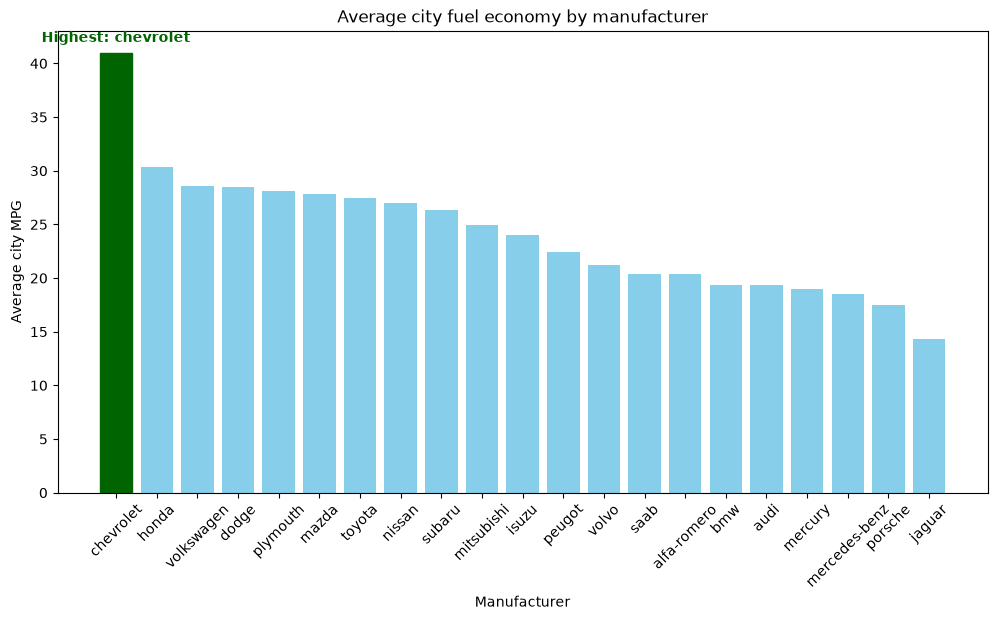

In [17]:
fuel_efficiency = automobiles_df.groupby('make')['city-mpg'].mean().sort_values(ascending=False)

plt.figure(figsize=(12,6))
bars = plt.bar(fuel_efficiency.index, fuel_efficiency.values, color='skyblue')

chevy_index = list(fuel_efficiency.index).index('chevrolet')
bars[chevy_index].set_color('#006400')  # Dark green

plt.title('Average city fuel economy by manufacturer')
plt.xlabel('Manufacturer')
plt.ylabel('Average city MPG')
plt.xticks(rotation=45)

plt.text(chevy_index, fuel_efficiency.max()+1, 'Highest: chevrolet',
         ha='center', color='#006400', fontweight='bold')

plt.show()



#### Which vehicles have the largest engine capacity.
Sort the dataframe based on the engine-size column.

In [10]:

largest_engines = automobiles_df.sort_values(by='engine-size', ascending=False)
print("Vehicles with the largest engine capacity:")
print(largest_engines[['make', 'engine-size', 'fuel-type']].head(5))

Vehicles with the largest engine capacity:
             make  engine-size fuel-type
49         jaguar          326       gas
73  mercedes-benz          308       gas
74  mercedes-benz          304       gas
48         jaguar          258       gas
47         jaguar          258       gas


#### Which vehicle manufacturer has the most car models in the dataset

In [11]:

model_counts = automobiles_df['make'].value_counts()

print("Number of car models per manufacturer:")
print(model_counts)

most_common = model_counts.idxmax()
count = model_counts.max()

print(f"The manufacturer with the most models is {most_common} with {count} entries.")



Number of car models per manufacturer:
make
toyota           32
nissan           18
honda            13
mitsubishi       13
volkswagen       12
subaru           12
mazda            12
volvo            11
peugot           11
bmw               8
dodge             8
mercedes-benz     8
plymouth          7
saab              6
audi              6
porsche           4
alfa-romero       3
jaguar            3
chevrolet         3
isuzu             2
mercury           1
Name: count, dtype: int64
The manufacturer with the most models is toyota with 32 entries.


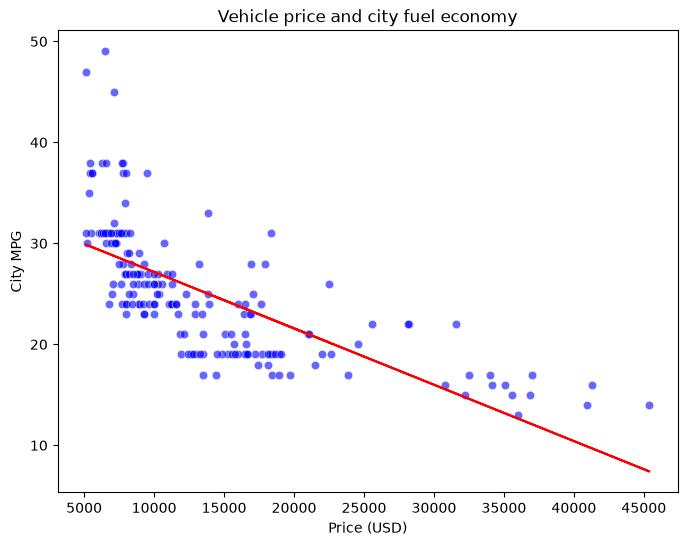

Pearson correlation between price and city MPG: r = -0.71


In [15]:
plt.figure(figsize=(8,6))
sns.scatterplot(x='price', y='city-mpg', data=automobiles_df, color='blue', alpha=0.6)

x = automobiles_df['price']
y = automobiles_df['city-mpg']
m, b = np.polyfit(x, y, 1)
plt.plot(x, m*x + b, color='red')

plt.title('Vehicle price and city fuel economy')
plt.xlabel('Price (USD)')
plt.ylabel('City MPG')
plt.show()

corr, p_value = pearsonr(x, y)
print(f"Pearson correlation between price and city MPG: r = {corr:.2f}")




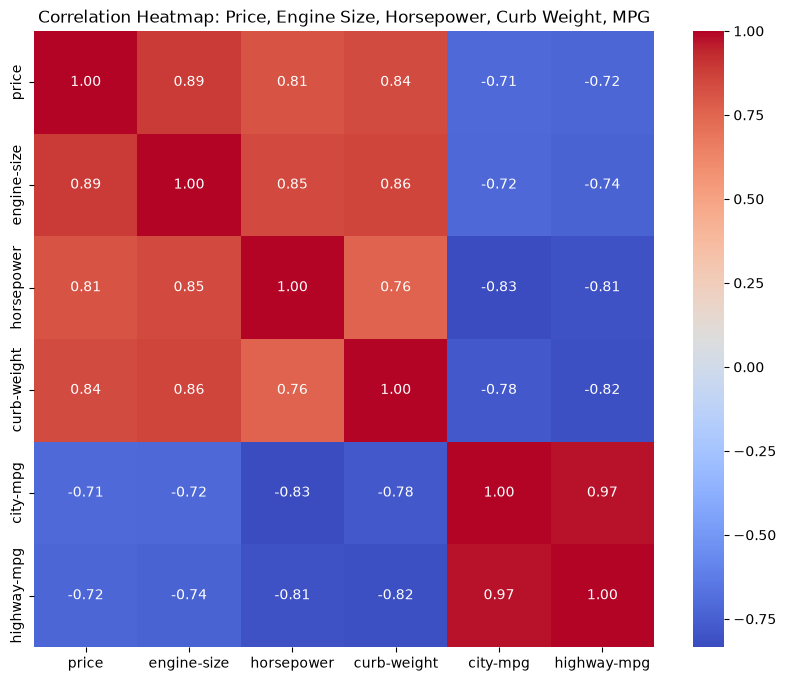

In [13]:
numeric_cols = ['price', 'engine-size', 'horsepower', 'curb-weight', 'city-mpg', 'highway-mpg']
corr_matrix = automobiles_df[numeric_cols].corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap: Price, Engine Size, Horsepower, Curb Weight, MPG')
plt.show()
